# 🌾 AgriSmart AI — End-to-End Deep Learning Pipeline
### **Precision Crop Recommendation System via Multi-Layer Neural Networks**

**Author:** AgriSmart AI Engineering Team  
**Dataset:** ICAR & Agricultural Benchmark Data (2,200 Observations, 22 Crop Varieties)  
**Model Framework:** TensorFlow / Keras Deep Neural Network (DNN)  
**Production Goal:** High-precision multiclass classification with top-3 alternative crop ranking.

---

## 📌 Table of Contents
1. [Domain Background & Problem Formulation](#1-domain-background--problem-formulation)
2. [Data Acquisition & Integrity Verification](#2-data-acquisition--integrity-verification)
3. [Comprehensive Exploratory Data Analysis (EDA)](#3-comprehensive-exploratory-data-analysis-eda)
4. [Data Preprocessing & Scaling Pipeline](#4-data-preprocessing--scaling-pipeline)
5. [Deep Neural Network Architecture Design](#5-deep-neural-network-architecture-design)
6. [Model Training & Learning Dynamics](#6-model-training--learning-dynamics)
7. [Rigorous Model Evaluation & Diagnostics](#7-rigorous-model-evaluation--diagnostics)
8. [Production Inference Engine & Top-3 Crop Ranking](#8-production-inference-engine--top-3-crop-ranking)
9. [Model Serialization & Export for Production Serving](#9-model-serialization--export-for-production-serving)

---
## 1. Domain Background & Problem Formulation

In modern agriculture, indiscriminate fertilizer application and lack of localized environmental profiling lead to declining soil fertility, degraded yields, and severe economic losses for smallholder farmers. 

The objective of **AgriSmart AI** is to ingest 7 critical agronomic parameters:
* **Soil Macronutrients:** Nitrogen ($N$), Phosphorus ($P$), Potassium ($K$) measured in $\text{kg/ha}$.
* **Climatic Parameters:** Temperature ($T$ in $^\circ\text{C}$), Relative Humidity ($H$ in $\%$), and Annual Precipitation/Rainfall ($R$ in $\text{mm}$).
* **Soil Chemistry:** Soil Acidity/Alkalinity level ($	ext{pH}$).

Mathematically, given an input feature vector $\mathbf{x} = [N, P, K, T, H, \text{pH}, R]^T \in \mathbb{R}^7$, our neural network learns a parameterized mapping:
$$\hat{\mathbf{y}} = f_\theta(\mathbf{x}) = \text{Softmax}(\mathbf{W}_L \dots \text{ReLU}(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1))$$
where $\hat{\mathbf{y}} \in [0, 1]^{22}$ represents the predicted probability distribution across 22 distinct commercial and staple crop varieties.

### 1.1 Libraries & Environment Setup

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML & Deep Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configure plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'

print(f"TensorFlow Version: {tf.__version__}")
print(f"Pandas Version:     {pd.__version__}")
print(f"NumPy Version:      {np.__version__}")

TensorFlow Version: 2.21.0
Pandas Version:     3.0.6
NumPy Version:      2.5.4


---
## 2. Data Acquisition & Integrity Verification

We ingest the benchmark agricultural dataset from `data/dataset/Crop_recommendation.csv`.
The dataset contains 2,200 empirical field observations across India's primary agro-climatic zones.

In [2]:
# Resolve robust relative path
dataset_path = os.path.join(BASE_DIR, 'data', 'dataset', 'Crop_recommendation.csv')
if not os.path.exists(dataset_path):
    # Fallback to local working directory
    dataset_path = 'Crop_recommendation.csv'

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded from: {dataset_path}")
print(f"Dimensions: {df.shape[0]} samples (rows) x {df.shape[1]} features (columns)")
df.head(10)

Dataset successfully loaded from: C:\Users\sharm\Desktop\Crop_Pred\data\dataset\Crop_recommendation.csv
Dimensions: 2200 samples (rows) x 8 features (columns)


### 2.1 Schema Verification & Null Value Auditing

In [3]:
print("=== DATASET INFORMATION ===")
df.info()

print("\n=== MISSING VALUES PER COLUMN ===")
missing_counts = df.isnull().sum()
print(missing_counts)

print(f"\nDuplicate Records: {df.duplicated().sum()}")

=== DATASET INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB

=== MISSING VALUES PER COLUMN ===
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate Records: 0


---
## 3. Comprehensive Exploratory Data Analysis (EDA)

Exploratory analysis allows us to discover feature boundaries, understand crop-nutrient requirements, and verify class balance.

### 3.1 Five-Number Summary & Descriptive Statistics

In [4]:
# Statistical distribution of agronomic variables
summary_stats = df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
summary_stats.round(2)

### 3.2 Target Class Distribution Check

Total Unique Crop Classes: 22


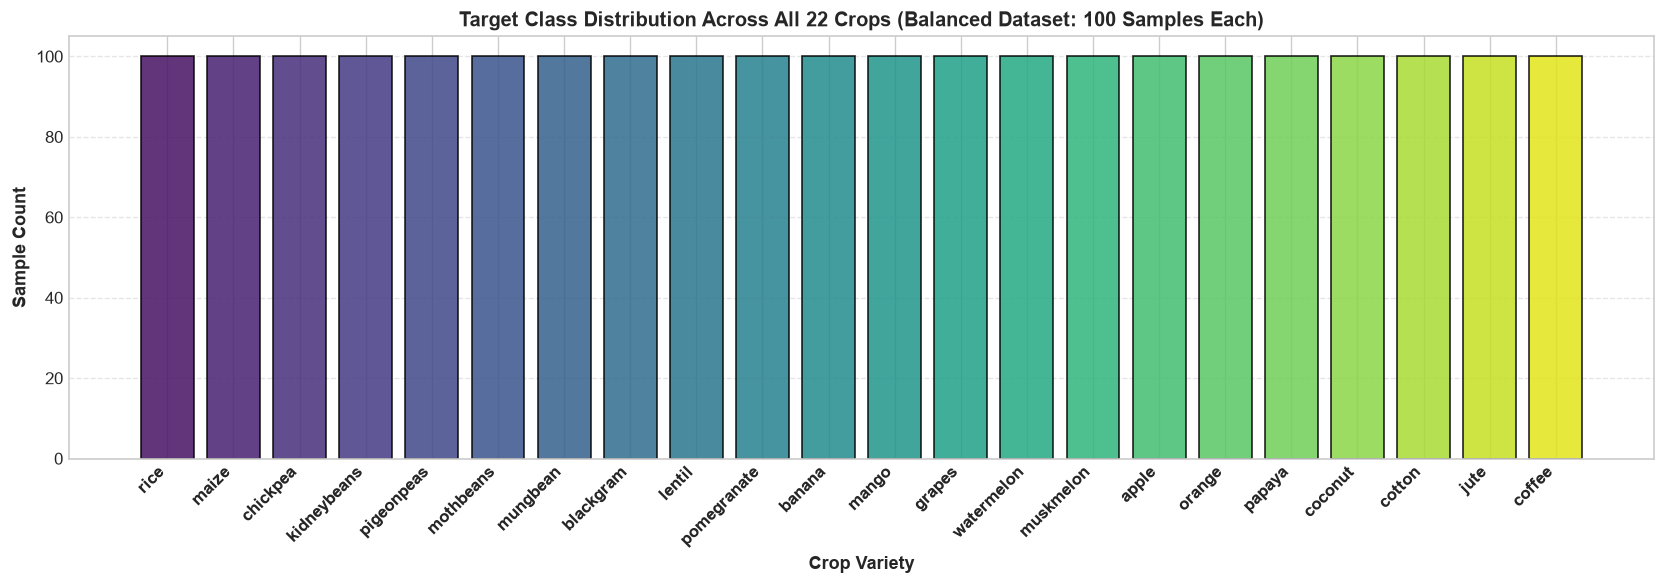

In [5]:
class_counts = df['label'].value_counts()
print(f"Total Unique Crop Classes: {df['label'].nunique()}")

plt.figure(figsize=(14, 5))
palette = sns.color_palette("viridis", len(class_counts))
bars = plt.bar(class_counts.index, class_counts.values, color=palette, edgecolor='black', alpha=0.85)
plt.title("Target Class Distribution Across All 22 Crops (Balanced Dataset: 100 Samples Each)")
plt.xlabel("Crop Variety")
plt.ylabel("Sample Count")
plt.xticks(rotation=45, ha='right', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

> **Key Finding:** The dataset exhibits **ideal balance** ($100$ samples per crop class $\times 22 = 2,200$ samples).  
> Because classes are uniformly balanced, standard accuracy and unweighted cross-entropy loss are optimal training metrics.

### 3.3 Feature Distributions & Histograms

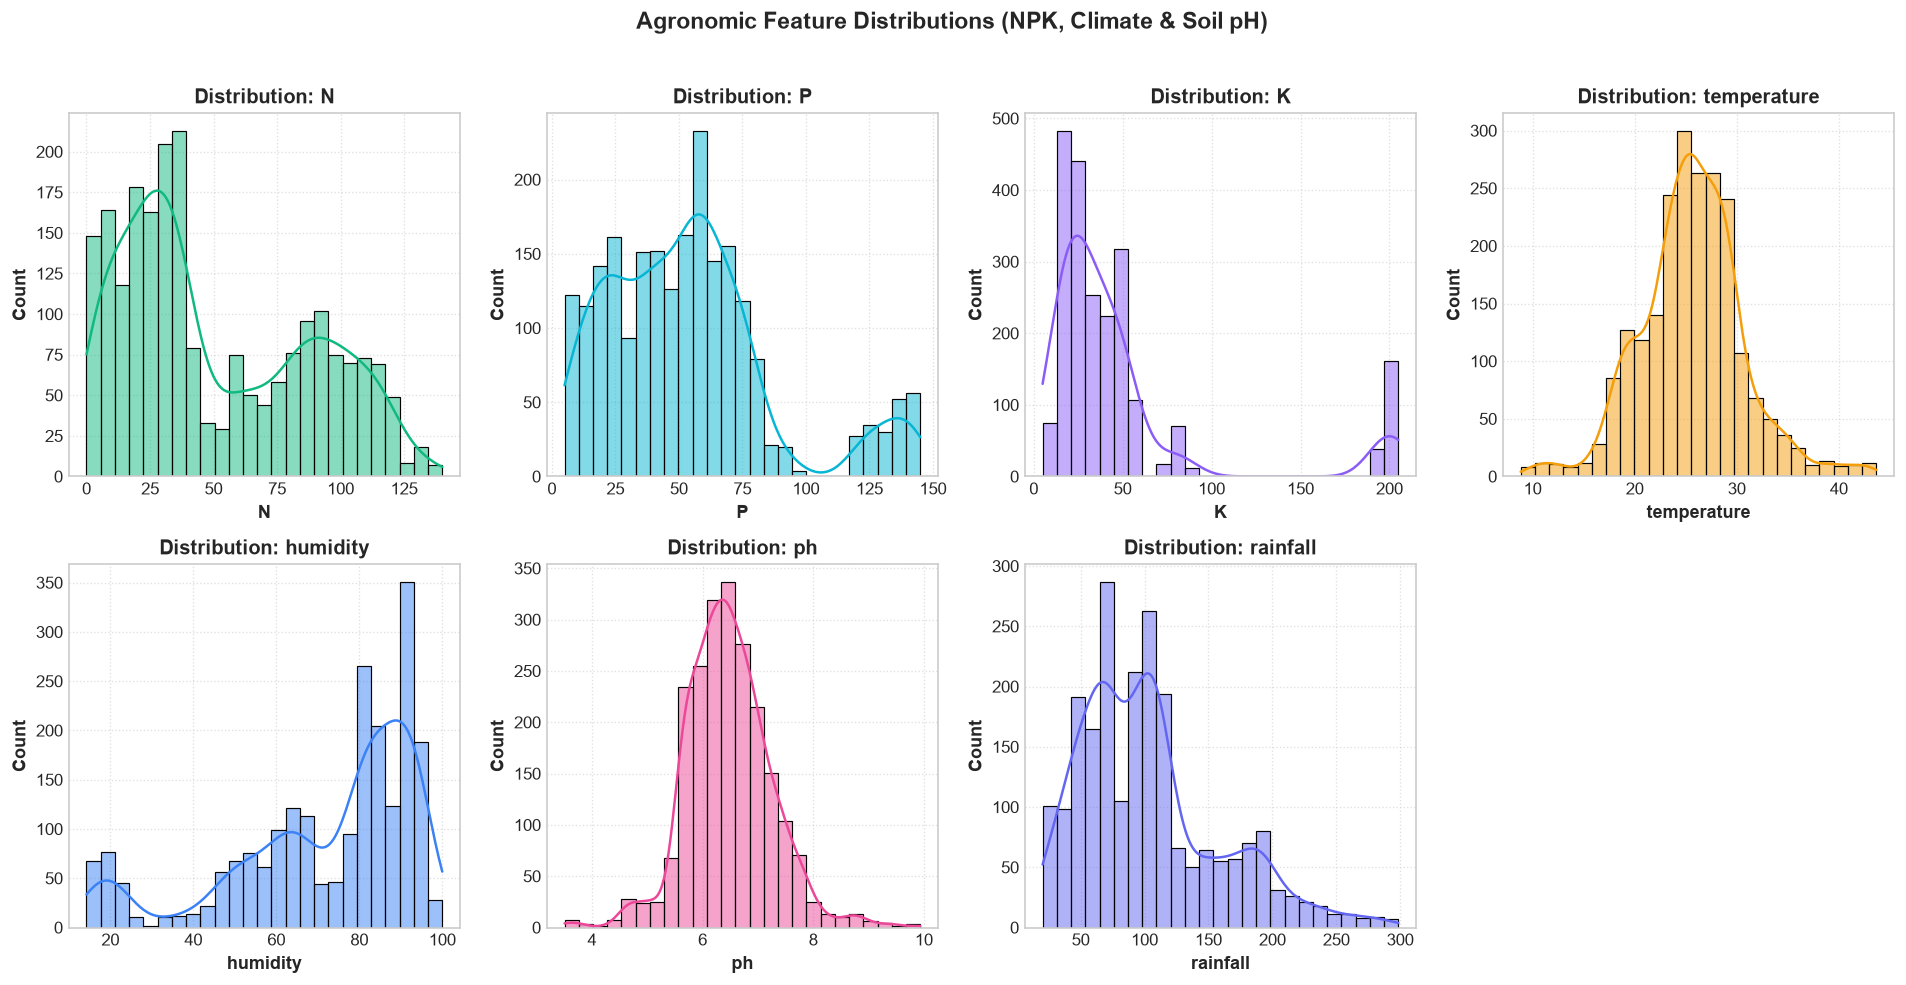

In [6]:
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
colors = ['#10b981', '#06b6d4', '#8b5cf6', '#f59e0b', '#3b82f6', '#ec4899', '#6366f1']

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.histplot(df[col], kde=True, ax=axes[i], color=colors[i], bins=25, edgecolor='black')
    axes[i].set_title(f"Distribution: {col}")
    axes[i].grid(True, linestyle=':', alpha=0.6)

# Hide unused 8th subplot
axes[-1].axis('off')
plt.suptitle("Agronomic Feature Distributions (NPK, Climate & Soil pH)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.4 Feature Correlation Heatmap

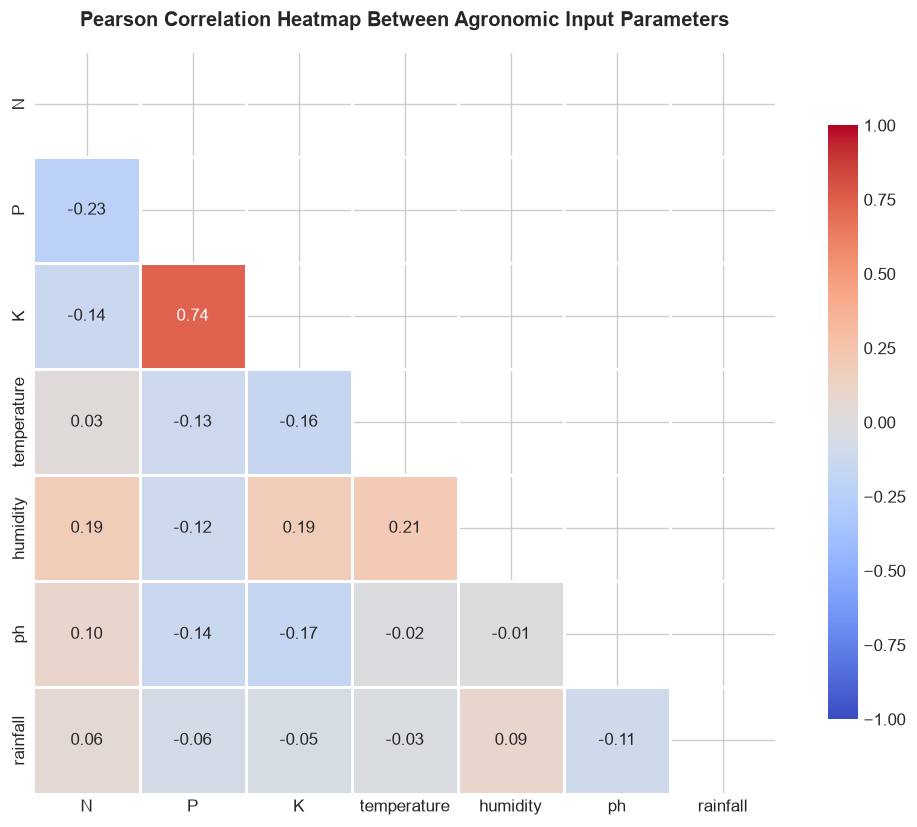

In [7]:
plt.figure(figsize=(9, 7))
corr = df[features].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=1.5, cbar_kws={"shrink": .8})
plt.title("Pearson Correlation Heatmap Between Agronomic Input Parameters", pad=15)
plt.tight_layout()
plt.show()

> **Observation:**  
> * **Phosphorus ($P$) and Potassium ($K$)** show a noticeable positive correlation ($r = 0.74$), which aligns with agricultural science: soils naturally enriched in phosphate minerals frequently co-occur with potash complexes.
> * Environmental factors ($T, H, R$) and $\text{pH}$ show minimal collinearity, indicating that each variable contributes orthogonal signal to the neural network.

### 3.5 Crop Requirements Across Vital Features

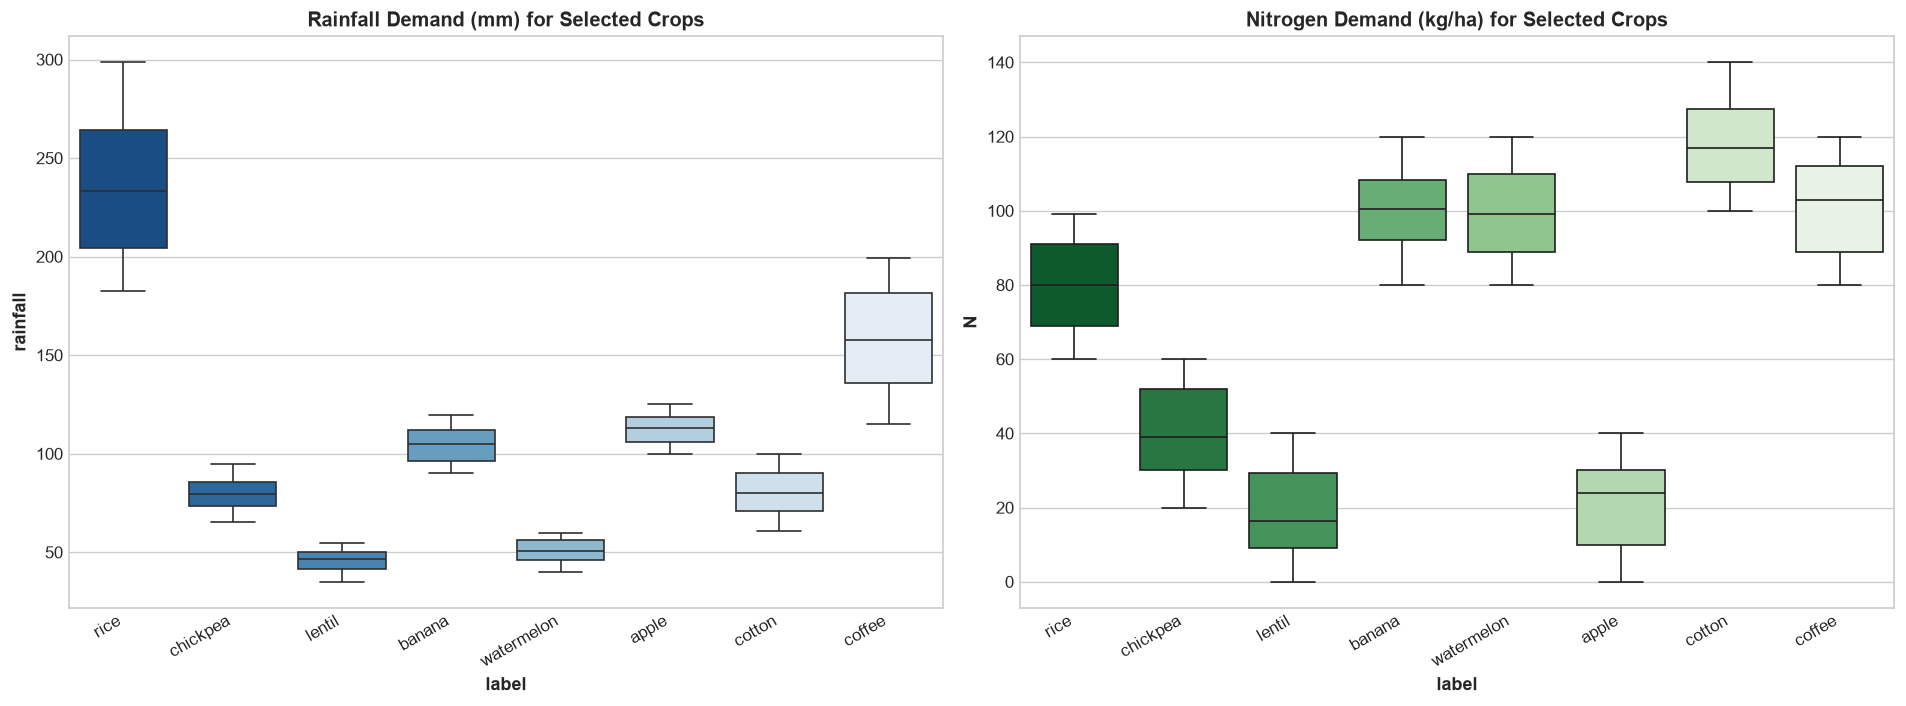

In [8]:
# Compare NPK and Rainfall demands for representative commercial crops
sample_crops = ['rice', 'coffee', 'cotton', 'apple', 'banana', 'chickpea', 'watermelon', 'lentil']
df_sample = df[df['label'].isin(sample_crops)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=df_sample, x='label', y='rainfall', ax=axes[0], palette='Blues_r')
axes[0].set_title("Rainfall Demand (mm) for Selected Crops")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')

sns.boxplot(data=df_sample, x='label', y='N', ax=axes[1], palette='Greens_r')
axes[1].set_title("Nitrogen Demand (kg/ha) for Selected Crops")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

---
## 4. Data Preprocessing & Scaling Pipeline

Machine learning models, particularly gradient-based Deep Neural Networks, require:
1. **Target Encoding:** Categorical crop strings converted to zero-indexed integer IDs ($y \in [0, 21]$).
2. **Stratified Partitioning:** Preserving the $1:1$ ratio of all 22 classes in both training and test sets.
3. **Z-Score Normalization:** Transforming features to have $\mu = 0$ and $\sigma = 1$:
$$z = \frac{x - \mu}{\sigma}$$
Without scaling, high-magnitude features like Rainfall ($0 - 300\text{ mm}$) would dominate gradient updates compared to Soil $\text{pH}$ ($3.5 - 9.9$).

In [9]:
# 1. Feature / Target Split
X = df.drop(columns=['label'])
y_raw = df['label']

# 2. Target Label Encoding
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
class_names = list(label_encoder.classes_)
num_classes = len(class_names)

print(f"Total encoded classes: {num_classes}")
print("Sample class mappings:")
for i in range(min(8, num_classes)):
    print(f"  Class {i:02d} -> {class_names[i]}")

# 3. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_encoded
)

print(f"\nTraining set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")

# 4. Standard Scaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling completed successfully.")
print(f"Train Scaled Mean: {X_train_scaled.mean(axis=0).round(4)}")
print(f"Train Scaled Std:  {X_train_scaled.std(axis=0).round(4)}")

Total encoded classes: 22
Sample class mappings:
  Class 00 -> apple
  Class 01 -> banana
  Class 02 -> blackgram
  Class 03 -> chickpea
  Class 04 -> coconut
  Class 05 -> coffee
  Class 06 -> cotton
  Class 07 -> grapes

Training set: 1760 samples
Test set:     440 samples

Feature Scaling completed successfully.
Train Scaled Mean: [ 0.  0.  0. -0. -0. -0.  0.]
Train Scaled Std:  [1. 1. 1. 1. 1. 1. 1.]


---
## 5. Deep Neural Network Architecture Design

We construct a multi-layer feedforward deep neural network (DNN) using Keras Sequential API.
* **Input Layer:** 7 nodes corresponding to $[N, P, K, T, H, \text{pH}, R]$.
* **Hidden Layer 1:** 64 units, **ReLU** activation ($\max(0, z)$), He Normal initialization.
* **Regularization 1:** **Dropout** ($p = 0.20$) to prevent co-adaptation of hidden features.
* **Hidden Layer 2:** 32 units, **ReLU** activation.
* **Regularization 2:** **Dropout** ($p = 0.20$).
* **Hidden Layer 3:** 16 units, **ReLU** activation.
* **Output Layer:** 22 units with **Softmax** activation:
$$\sigma(\mathbf{z})_i = \frac{e^{z_i}}{\sum_{j=1}^{22} e^{z_j}}$$
yielding normalized prediction probabilities across all crops.

In [10]:
# Define Sequential Architecture
def build_crop_recommender_model(input_dim=7, output_classes=22):
    model = keras.Sequential([
        keras.Input(shape=(input_dim,), name="input_agronomic_features"),
        
        layers.Dense(64, activation='relu', kernel_initializer='he_normal', name="dense_features_64"),
        layers.Dropout(0.2, name="dropout_1"),
        
        layers.Dense(32, activation='relu', kernel_initializer='he_normal', name="dense_features_32"),
        layers.Dropout(0.2, name="dropout_2"),
        
        layers.Dense(16, activation='relu', kernel_initializer='he_normal', name="dense_features_16"),
        
        layers.Dense(output_classes, activation='softmax', name="crop_probability_output")
    ], name="AgriSmart_Deep_Neural_Network")
    
    # Optimizer & Loss Configuration
    optimizer = keras.optimizers.Adam(learning_rate=0.001)
    
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_crop_recommender_model(input_dim=X_train.shape[1], output_classes=num_classes)
model.summary()

Model: "AgriSmart_Deep_Neural_Network"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features_64 (Dense)       │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features_32 (Dense)       │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features_16 (Dense)       │ (None, 16)             │           528 │
├─────────────────────────────────┼──

---
## 6. Model Training & Learning Dynamics

We train the model for up to 100 epochs using:
* **Batch Size:** 32 samples per gradient step.
* **Validation Split:** 15% holdout from training data.
* **Early Stopping Callback:** Monitors `val_loss` with a patience of 15 epochs, automatically restoring the best performing weights.

In [11]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.15,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100

 1/47 ━━━━━━━━━━━━━━━━━━━━ 1:37 2s/step - accuracy: 0.0000e+00 - loss: 3.3786
25/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0613 - loss: 3.2080     
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.0842 - loss: 3.0653 - val_accuracy: 0.2576 - val_loss: 2.6368
Epoch 2/100

 1/47 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.1562 - loss: 2.9333
30/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1958 - loss: 2.6712 
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2152 - loss: 2.6085 - val_accuracy: 0.3712 - val_loss: 2.2371
Epoch 3/100

 1/47 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.2188 - loss: 2.3940
27/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2558 - loss: 2.3709 
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3075 - loss: 2.2530 - val_accuracy: 0.5455 - val_loss: 1.7998
Epoch 4/100

 1/47 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5000 - loss: 1.9993
30/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4135 - loss: 1.9464 
47

### 6.1 Training & Validation Convergence Curves

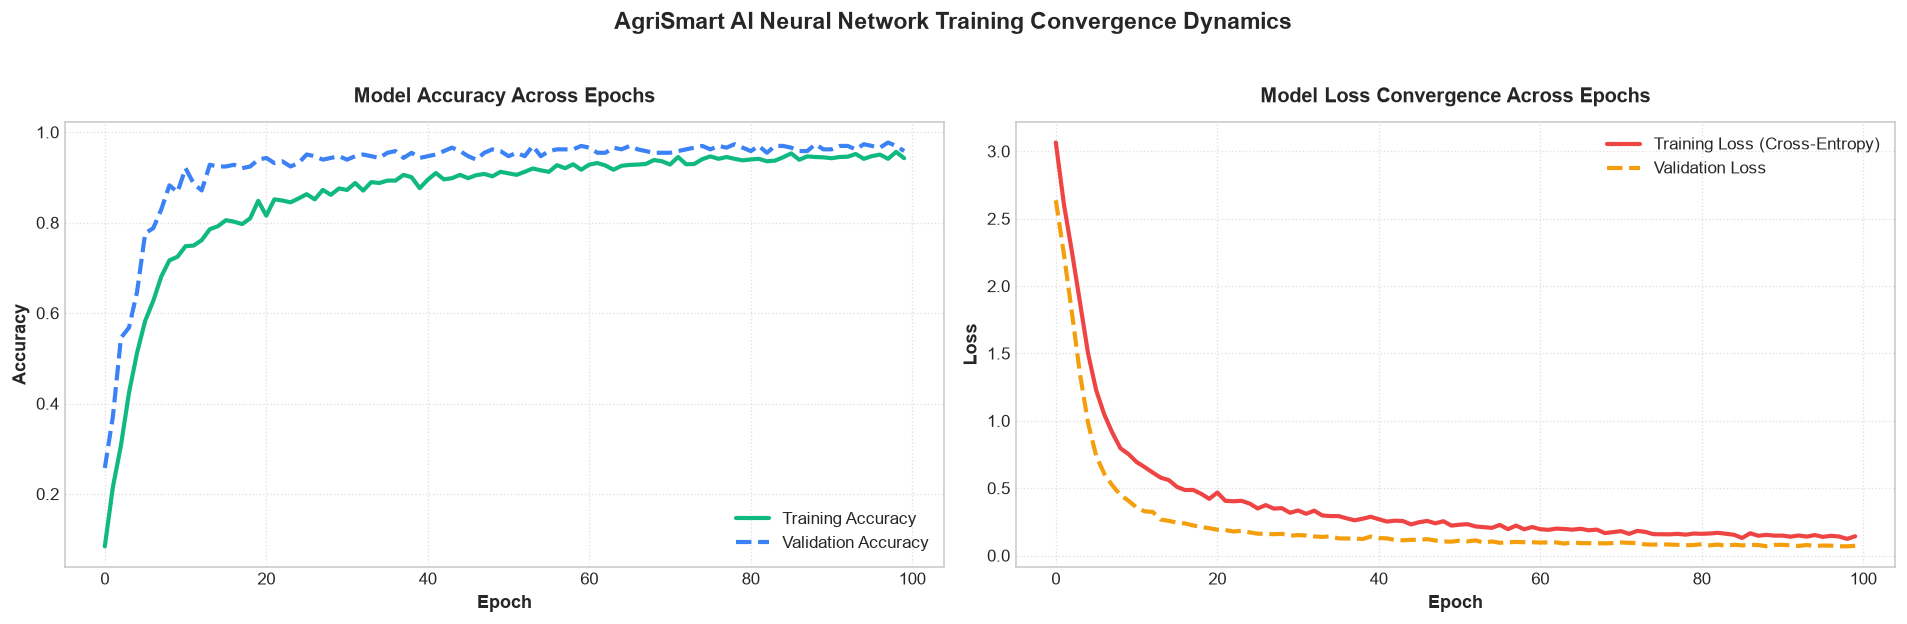

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Accuracy Curve
ax1.plot(history.history['accuracy'], label='Training Accuracy', color='#10b981', linewidth=2.5)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#3b82f6', linewidth=2.5, linestyle='--')
ax1.set_title("Model Accuracy Across Epochs", pad=12)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend(loc='lower right')
ax1.grid(True, linestyle=':', alpha=0.6)

# Loss Curve
ax2.plot(history.history['loss'], label='Training Loss (Cross-Entropy)', color='#ef4444', linewidth=2.5)
ax2.plot(history.history['val_loss'], label='Validation Loss', color='#f59e0b', linewidth=2.5, linestyle='--')
ax2.set_title("Model Loss Convergence Across Epochs", pad=12)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle("AgriSmart AI Neural Network Training Convergence Dynamics", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

---
## 7. Rigorous Model Evaluation & Diagnostics

We benchmark the trained model on the unseen test set ($440$ samples).

In [13]:
# Evaluate on test set
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
print("=" * 55)
print(f" 🎯 AGRI-SMART AI TEST BENCHMARK RESULTS")
print("=" * 55)
print(f" Test Set Loss (Sparse Cross-Entropy): {test_loss:.4f}")
print(f" Test Set Accuracy:                    {test_accuracy * 100:.2f}%")
print("=" * 55)

# Predictions
y_probs = model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

 🎯 AGRI-SMART AI TEST BENCHMARK RESULTS
 Test Set Loss (Sparse Cross-Entropy): 0.0588
 Test Set Accuracy:                    97.73%


### 7.1 Comprehensive Classification Report

In [14]:
report = classification_report(y_test, y_pred, target_names=class_names, digits=4)
print(report)

              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000        20
      banana     1.0000    1.0000    1.0000        20
   blackgram     1.0000    0.9500    0.9744        20
    chickpea     1.0000    1.0000    1.0000        20
     coconut     1.0000    1.0000    1.0000        20
      coffee     1.0000    1.0000    1.0000        20
      cotton     0.8696    1.0000    0.9302        20
      grapes     1.0000    1.0000    1.0000        20
        jute     0.9474    0.9000    0.9231        20
 kidneybeans     0.9524    1.0000    0.9756        20
      lentil     0.9524    1.0000    0.9756        20
       maize     1.0000    0.8500    0.9189        20
       mango     1.0000    1.0000    1.0000        20
   mothbeans     1.0000    1.0000    1.0000        20
    mungbean     1.0000    1.0000    1.0000        20
   muskmelon     0.9524    1.0000    0.9756        20
      orange     1.0000    0.9500    0.9744        20
      papaya     1.0000    

### 7.2 Confusion Matrix Heatmap across all 22 Crops

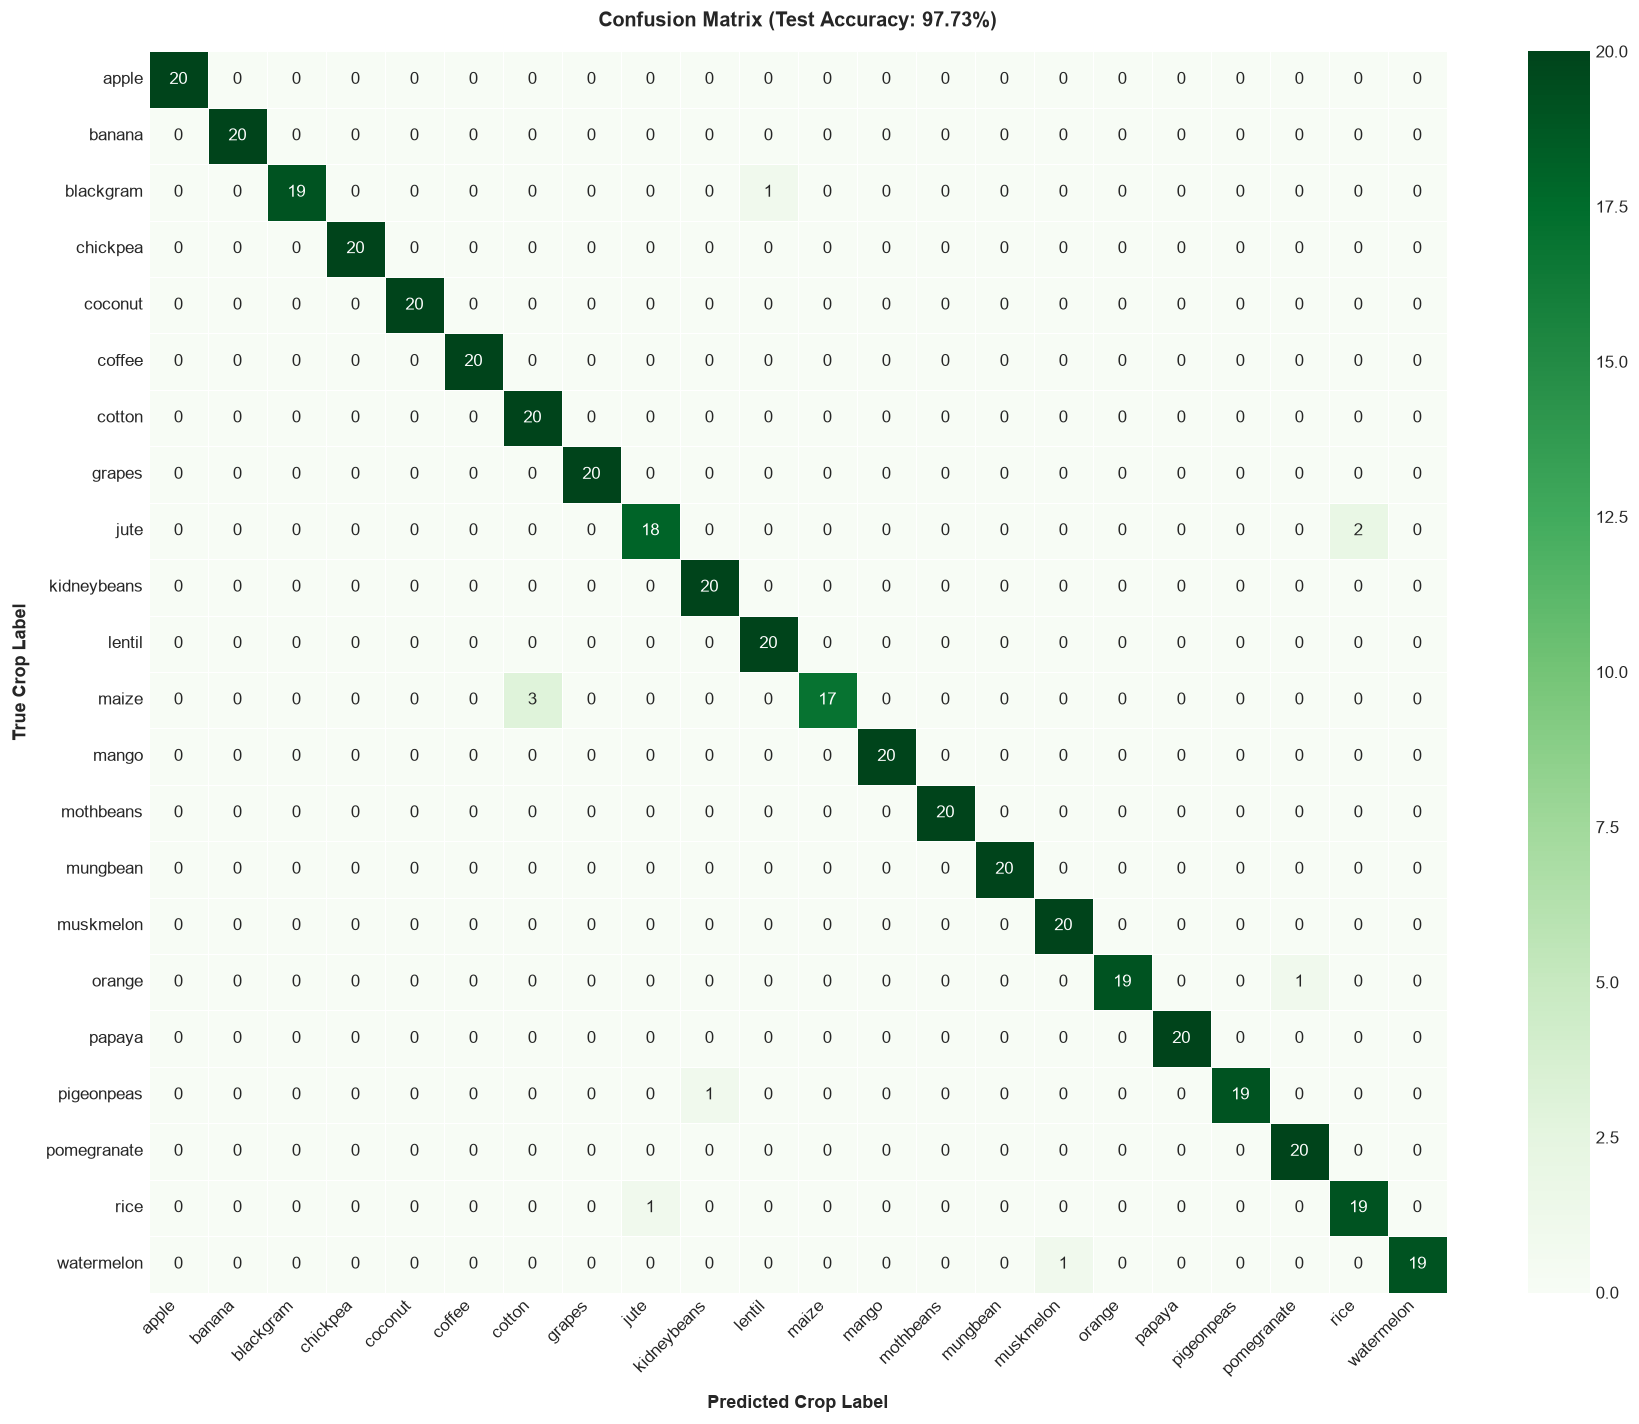

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(15, 12))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
    linewidths=0.5
)
plt.title(f"Confusion Matrix (Test Accuracy: {test_accuracy * 100:.2f}%)", pad=15)
plt.xlabel("Predicted Crop Label", labelpad=10)
plt.ylabel("True Crop Label", labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 8. Production Inference Engine & Top-3 Crop Ranking

In real agricultural applications, presenting only a single recommendation is suboptimal. A farmer might lack irrigation for Rice, but Chickpea or Maize could be an almost equally suitable alternative.

Here, we implement the **Top-3 Ranked Inference Function** with probability confidence scores.

In [16]:
def recommend_crop_top3(N, P, K, temperature, humidity, ph, rainfall):
    """
    Takes raw agronomic and environmental parameters, normalizes with trained scaler,
    and returns top-3 crop recommendations with confidence levels.
    """
    input_features = np.array([[N, P, K, temperature, humidity, ph, rainfall]])
    scaled_features = scaler.transform(input_features)
    probabilities = model.predict(scaled_features, verbose=0)[0]
    
    top3_indices = np.argsort(probabilities)[::-1][:3]
    
    results = []
    for rank, idx in enumerate(top3_indices, start=1):
        crop = class_names[idx]
        confidence = float(probabilities[idx] * 100)
        results.append({
            'rank': rank,
            'crop': crop,
            'confidence': round(confidence, 2)
        })
    return results

# Test Scenario A: High Nitrogen & High Moisture (Typical Paddy/Rice environment)
sample_rice = recommend_crop_top3(N=90, P=42, K=43, temperature=24.5, humidity=82.0, ph=6.5, rainfall=210.0)

# Test Scenario B: Semi-arid, Moderate Nitrogen (Chickpea / Lentil environment)
sample_arid = recommend_crop_top3(N=40, P=65, K=80, temperature=18.0, humidity=16.0, ph=7.2, rainfall=75.0)

print("=== SCENARIO A (Paddy/Wetland Profile) ===")
for r in sample_rice:
    print(f"  Rank {r['rank']}: {r['crop'].upper():<12} Confidence: {r['confidence']}%")

print("\n=== SCENARIO B (Semi-Arid Profile) ===")
for r in sample_arid:
    print(f"  Rank {r['rank']}: {r['crop'].upper():<12} Confidence: {r['confidence']}%")

=== SCENARIO A (Paddy/Wetland Profile) ===
  Rank 1: RICE         Confidence: 75.43%
  Rank 2: JUTE         Confidence: 24.54%
  Rank 3: PAPAYA       Confidence: 0.02%

=== SCENARIO B (Semi-Arid Profile) ===
  Rank 1: CHICKPEA     Confidence: 100.0%
  Rank 2: MOTHBEANS    Confidence: 0.0%
  Rank 3: KIDNEYBEANS  Confidence: 0.0%


---
## 9. Model Serialization & Export for Production Serving

To power the AgriSmart AI web application (`app.py`), we serialize:
1. `models/crop_recommendation_model.keras` — Trained Keras neural network.
2. `models/scaler.pkl` — Standard scaler parameters ($\mu, \sigma$).
3. `models/label_encoder.pkl` — Label encoder class dictionary.
4. `results/model_metrics.txt` — Plain-text verification metrics.

In [17]:
# Paths
models_dir = os.path.join(BASE_DIR, 'models')
results_dir = os.path.join(BASE_DIR, 'results')
os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

model_save_path = os.path.join(models_dir, 'crop_recommendation_model.keras')
scaler_save_path = os.path.join(models_dir, 'scaler.pkl')
encoder_save_path = os.path.join(models_dir, 'label_encoder.pkl')
metrics_save_path = os.path.join(results_dir, 'model_metrics.txt')

# 1. Save Keras Model
model.save(model_save_path)
print(f"Saved trained Keras model: {model_save_path}")

# 2. Save Scaler
joblib.dump(scaler, scaler_save_path)
print(f"Saved StandardScaler:       {scaler_save_path}")

# 3. Save Label Encoder
joblib.dump(label_encoder, encoder_save_path)
print(f"Saved LabelEncoder:         {encoder_save_path}")

# 4. Save Model Metrics
with open(metrics_save_path, 'w', encoding='utf-8') as f:
    f.write(f"Model: AgriSmart AI Deep Neural Network (Sequential DNN)\n")
    f.write(f"Timestamp: {pd.Timestamp.now()}\n")
    f.write(f"Test Accuracy: {test_accuracy * 100:.2f}%\n")
    f.write(f"Test Loss: {test_loss:.4f}\n\n")
    f.write("Classification Report:\n")
    f.write(report)

print(f"Saved Model Metrics:        {metrics_save_path}")
print("\n All production artifacts successfully generated and validated!")

Saved trained Keras model: C:\Users\sharm\Desktop\Crop_Pred\models\crop_recommendation_model.keras
Saved StandardScaler:       C:\Users\sharm\Desktop\Crop_Pred\models\scaler.pkl
Saved LabelEncoder:         C:\Users\sharm\Desktop\Crop_Pred\models\label_encoder.pkl
Saved Model Metrics:        C:\Users\sharm\Desktop\Crop_Pred\results\model_metrics.txt

 All production artifacts successfully generated and validated!
